REINFORCE is a policy gradient RL algorithm, on-policy, Monte Carlo. 

It learns an optimal policy by directly optimizing the probability of selecting actions that maximize the expected cumulative reward. Instead of estimating value functions such as state values or action values, REINFORCE updates the policy parameters using the rewards collected from complete episodes.



**RE**ward **I**ncrement = **N**onnegative **F**actor × **O**ffset **R**einforcement × **C**haracteristic **E**ligibility

$\Delta \theta = \eta \underbrace{(G_t − b)}_{\text{learning signal}} \underbrace{\nabla \log \pi(a_t|s_t)}_{\text{eligibility trace}}$

- nonnegative factor is the learning rate $\eta$
- offset reinforcement is the advantage, i.e. the return $G$ minus the baseline $b$
- characteristic eligibility is $\nabla \log \pi(a_t|s_t)$


The advantage decides whether each step's action becomes more or less likely (its sign) and how strongly (its size). It doesn't decide which weights change or in which direction. That comes from $\nabla \log \pi(a_t|s_t)$

In [1]:
import os
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

import sys
sys.path.append('../src')

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import time

# JAX imports
import jax
import jax.numpy as jnp
import optax
from flax import nnx
import gymnax

# Custom imports
from jaxrl.models.mlp import MLP
from jaxrl.reinforce import compute_returns, rollout, train_step
from jaxrl.plot import plot_advantages, plot_policy

In [3]:
# Hyperparameters
GAMMA = 0.99
LR = 0.01
NUM_EPISODES = 1000
CHECK_STEP = 100
SEED = 0
BASELINE_DECAY = 0.9

# Environment parameters
OBS_SPACE = 4
ACT_SPACE = 2
MAX_STEPS = 500

# Random keys
main_key = jax.random.key(SEED)
main_key, model_key = jax.random.split(main_key, 2)

## Environment

In [4]:
env, env_params = gymnax.make("CartPole-v1")

## Model

In [5]:
model = MLP(OBS_SPACE, ACT_SPACE, rngs=nnx.Rngs(model_key))

## Optimizer

In [6]:
optimizer = nnx.Optimizer(model, optax.adam(LR), wrt=nnx.Param)

## Training

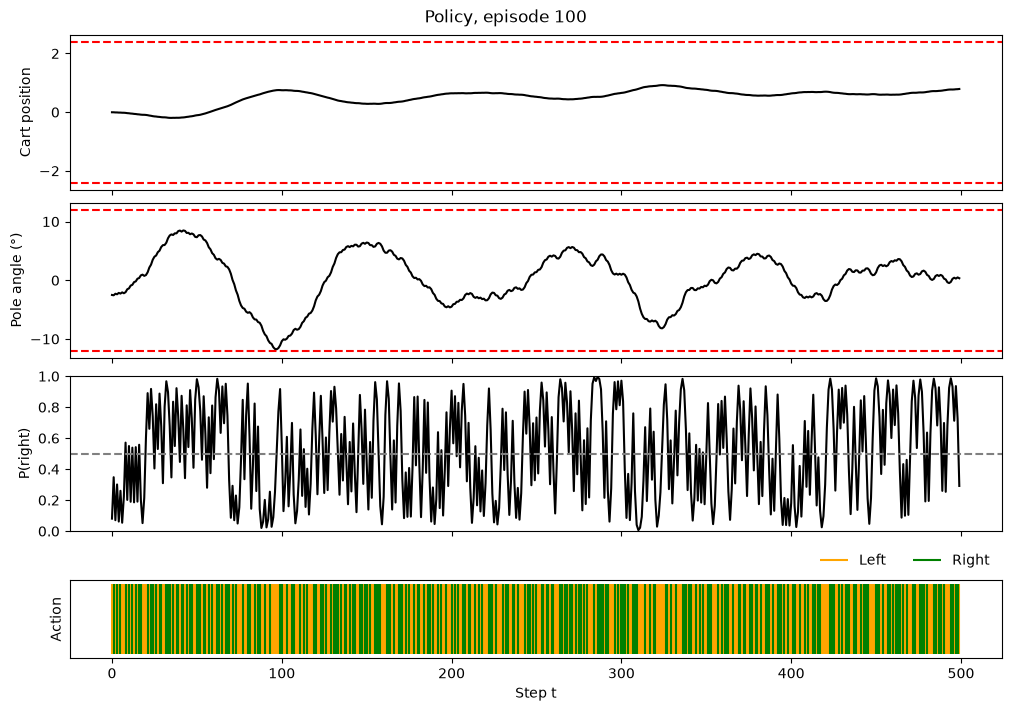

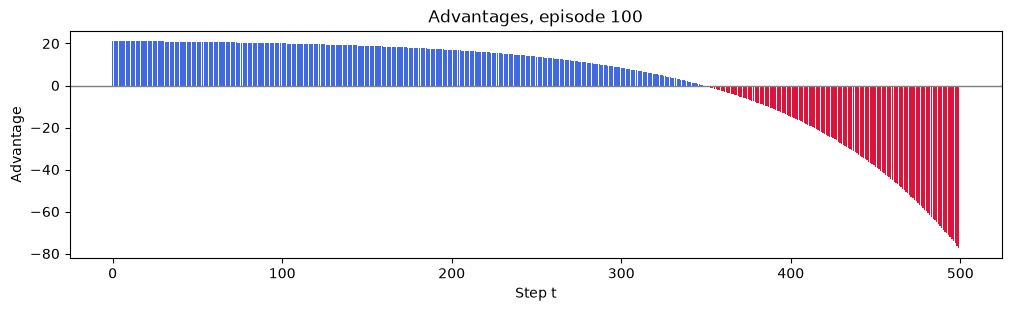

Episode  100 | return:  500.0 | loss: 0.3536


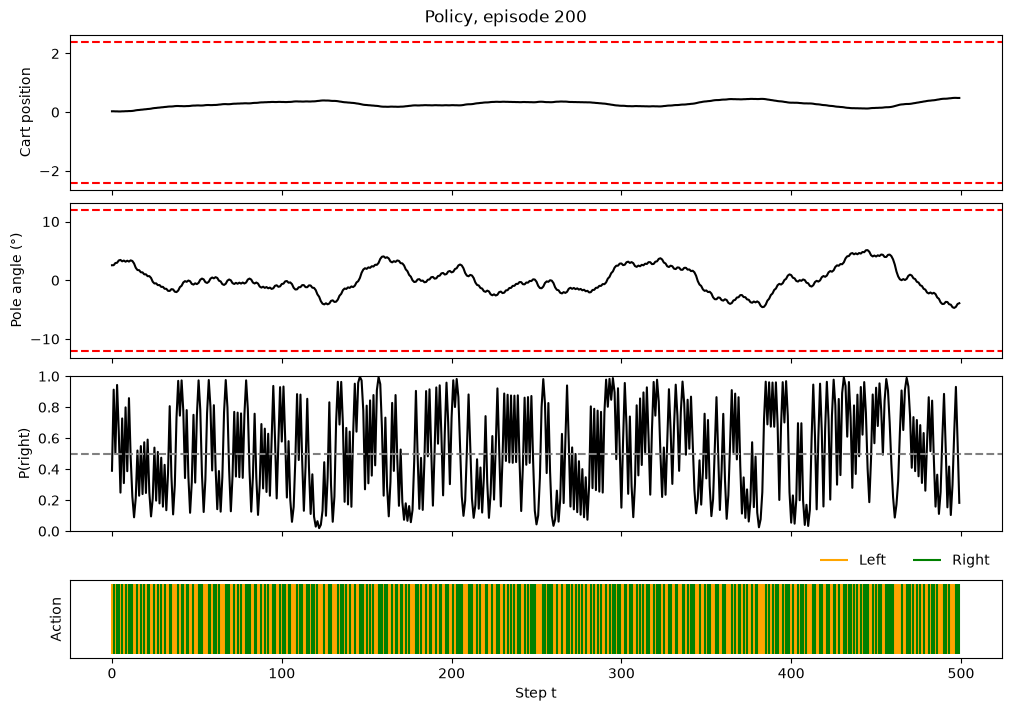

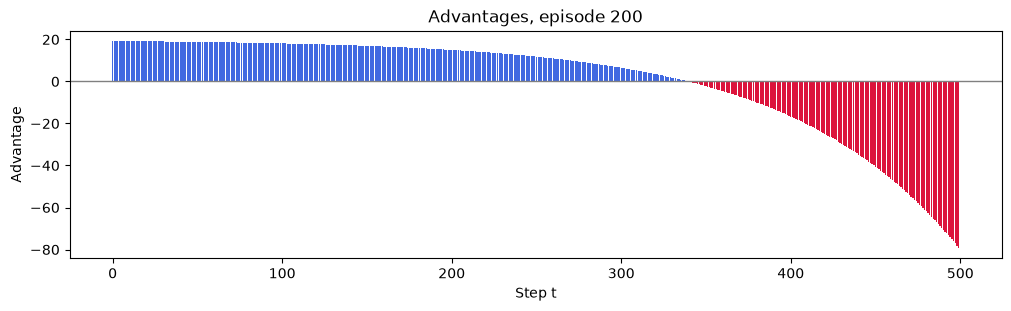

Episode  200 | return:  500.0 | loss: -0.1435


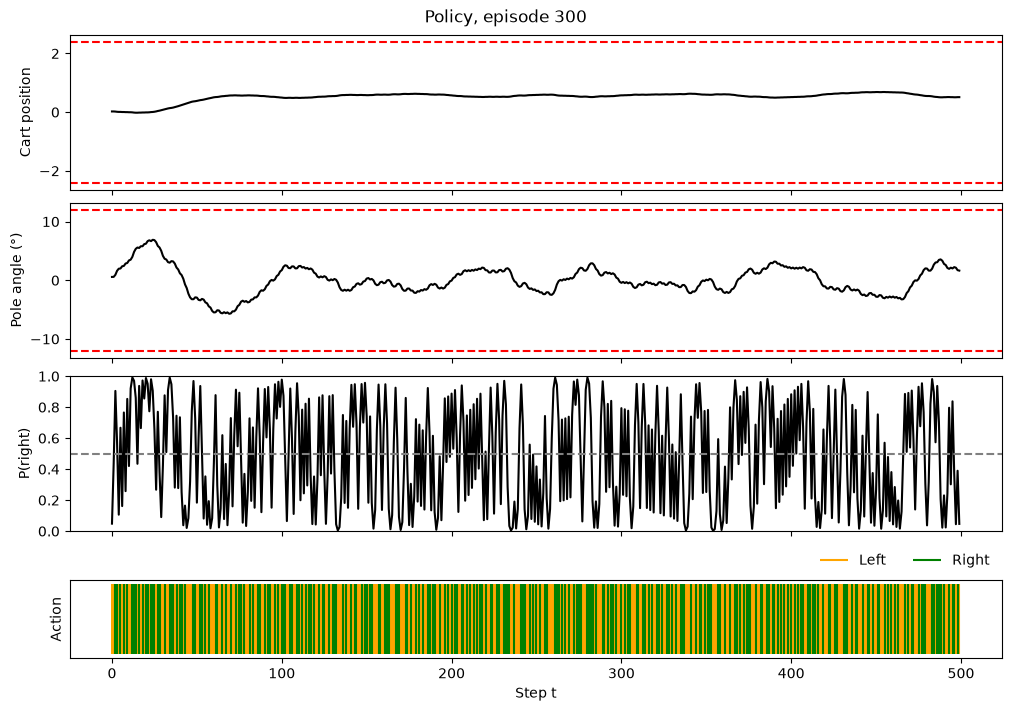

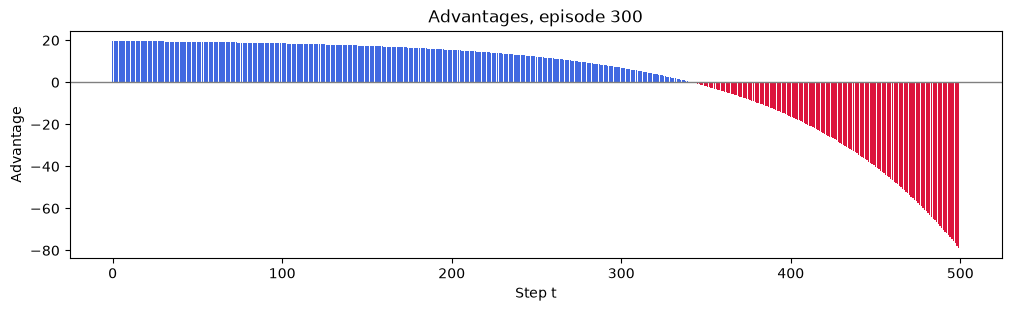

Episode  300 | return:  500.0 | loss: 0.2938


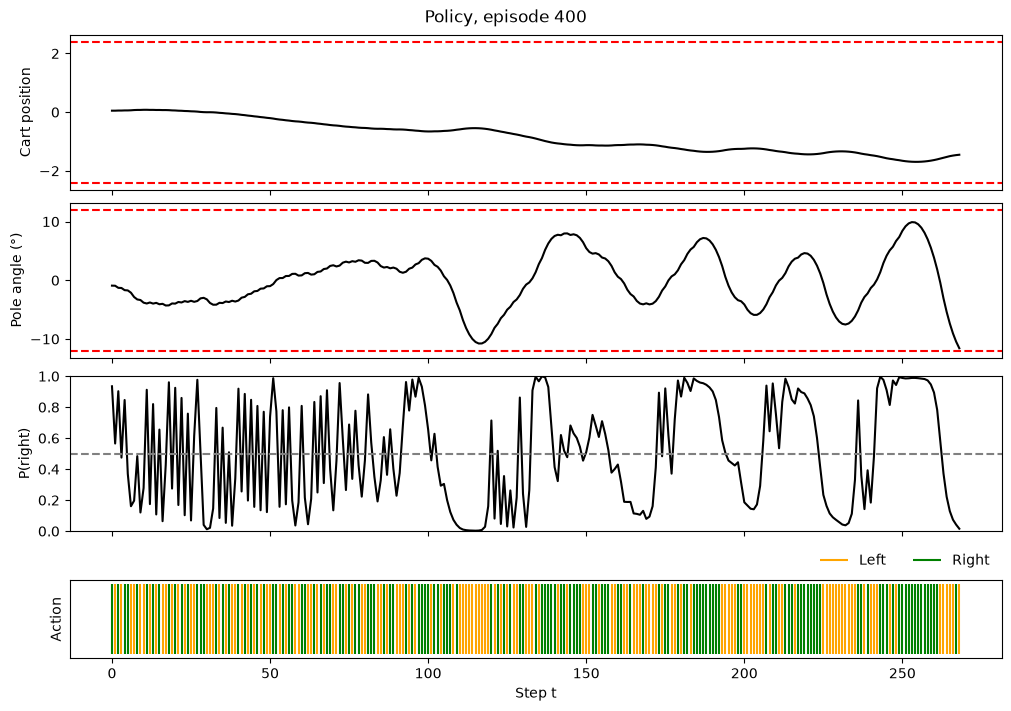

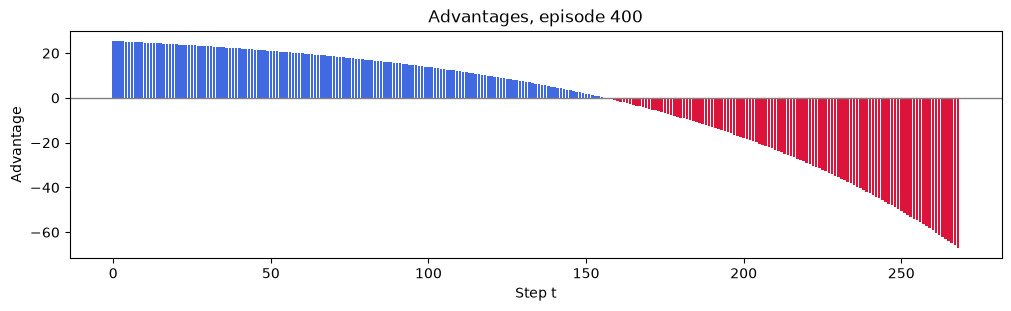

Episode  400 | return:  269.0 | loss: -1.0591


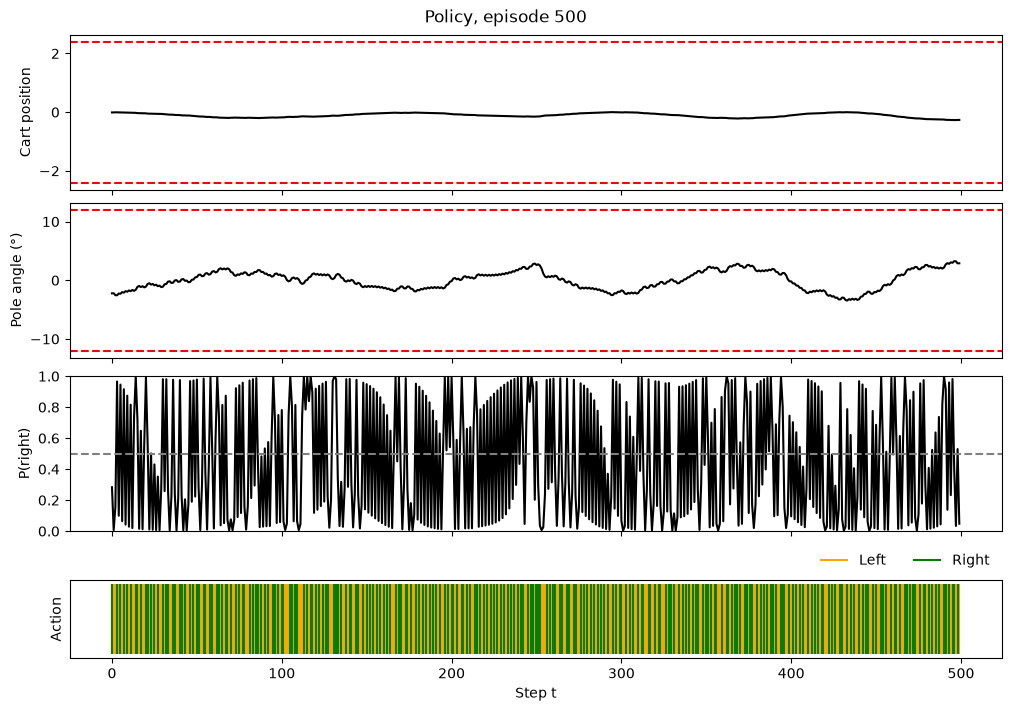

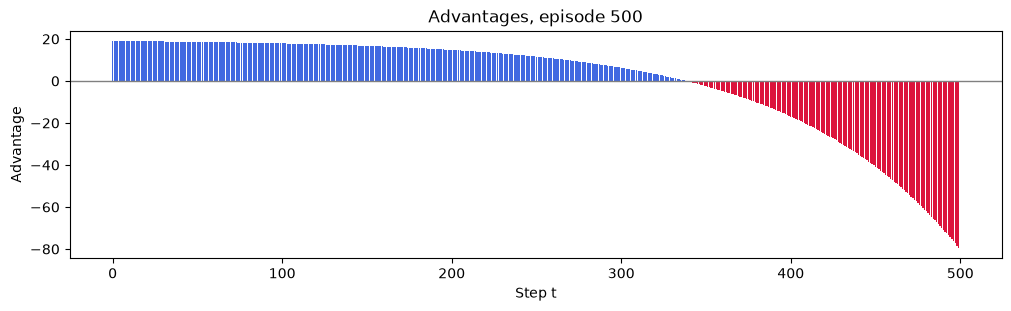

Episode  500 | return:  500.0 | loss: -0.0577


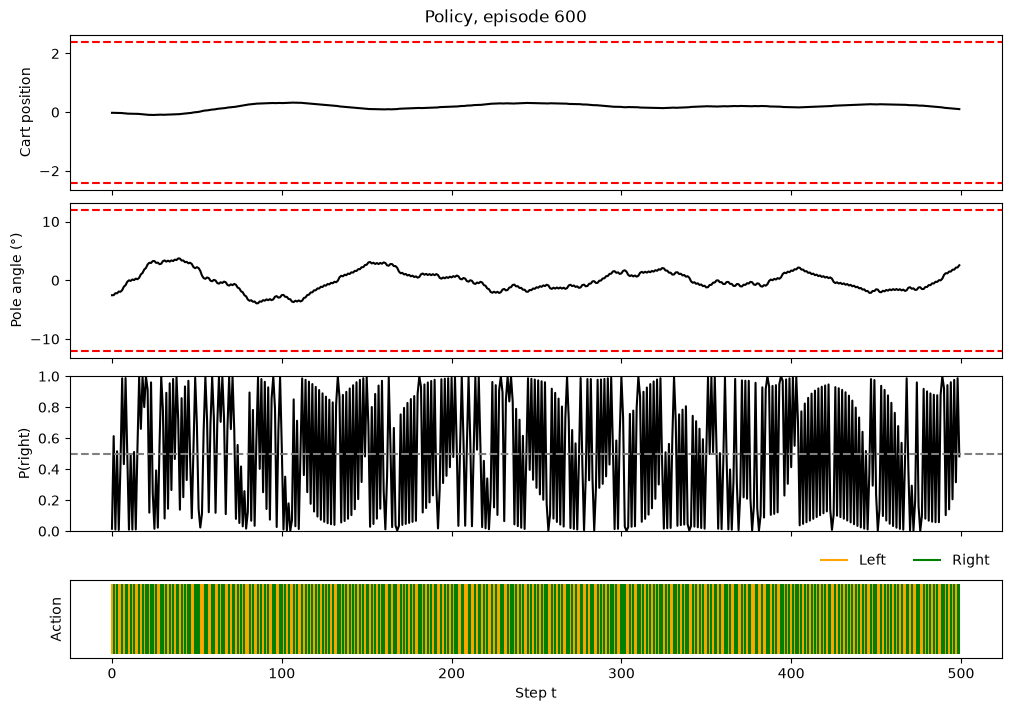

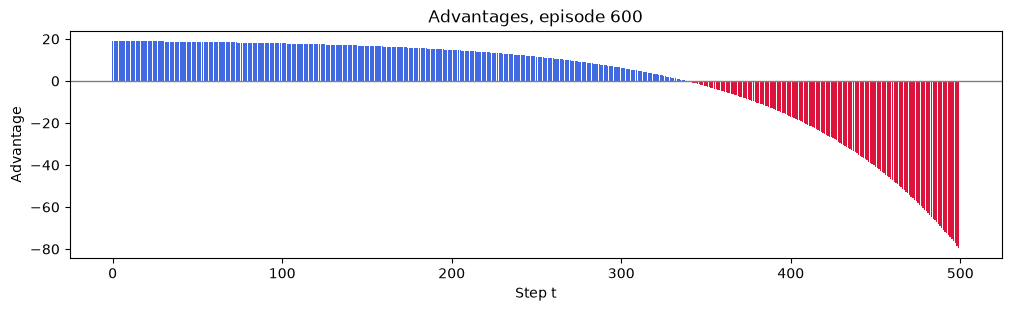

Episode  600 | return:  500.0 | loss: 0.5907


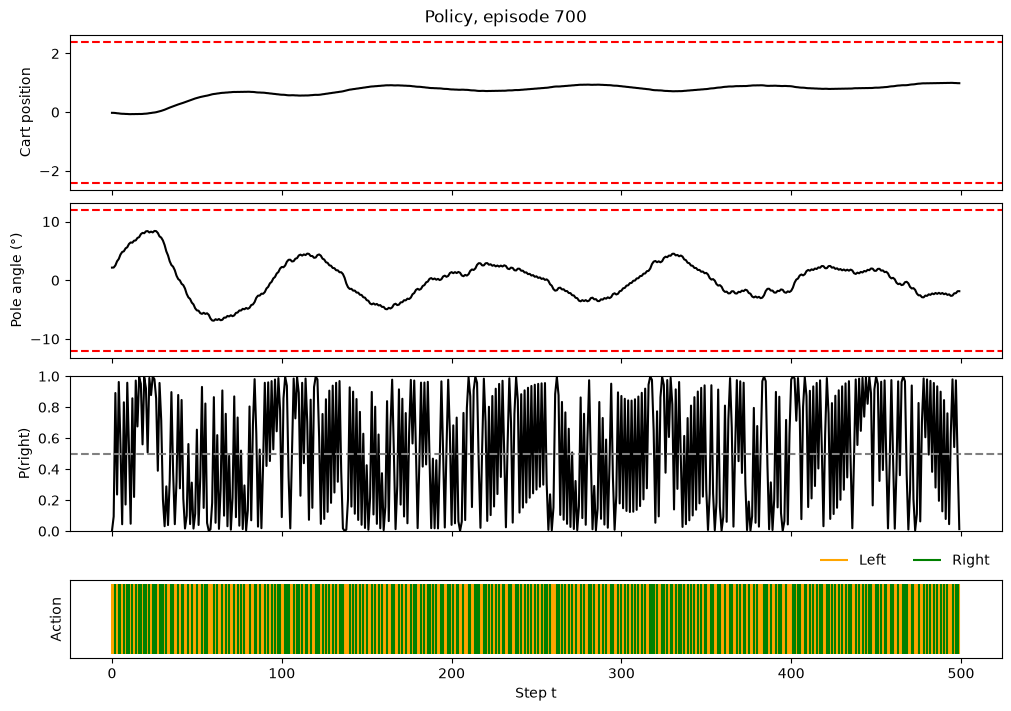

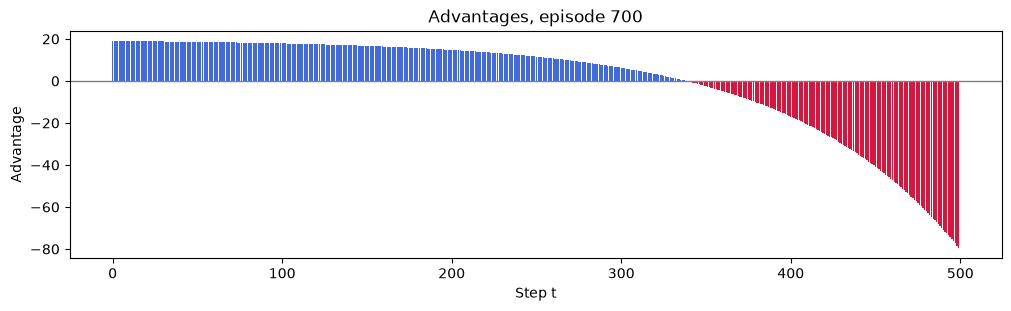

Episode  700 | return:  500.0 | loss: -0.5059


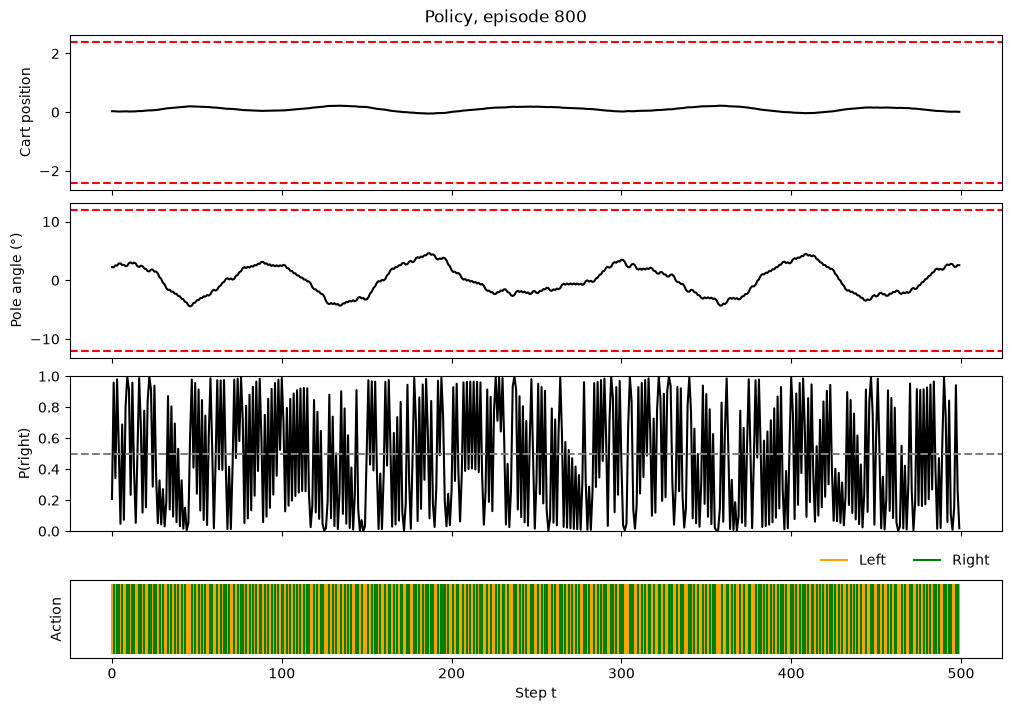

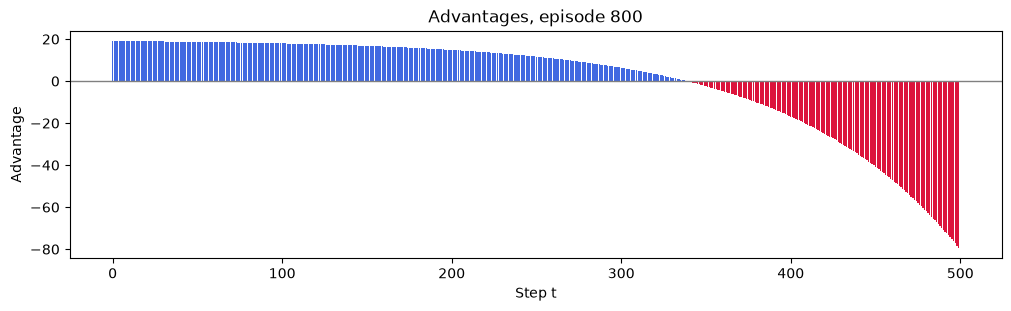

Episode  800 | return:  500.0 | loss: -0.0209


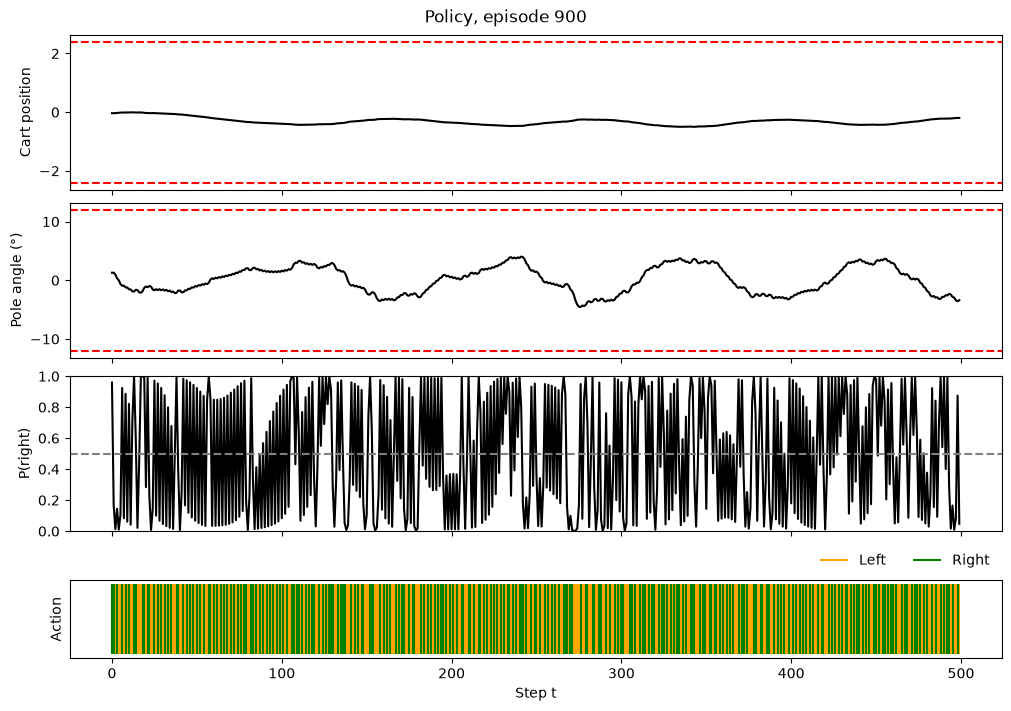

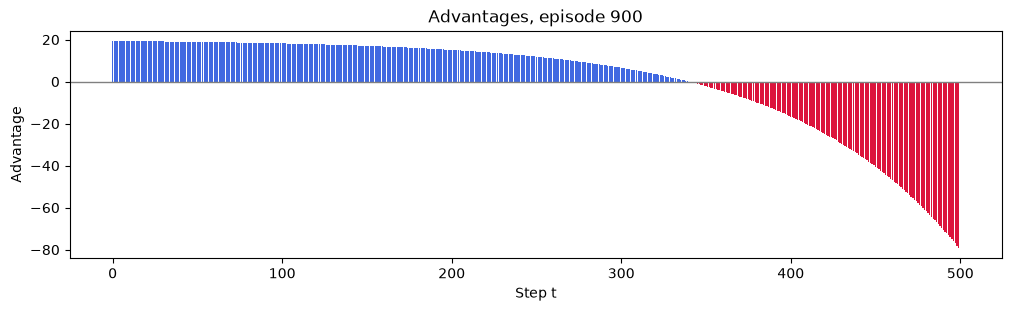

Episode  900 | return:  500.0 | loss: 0.2655


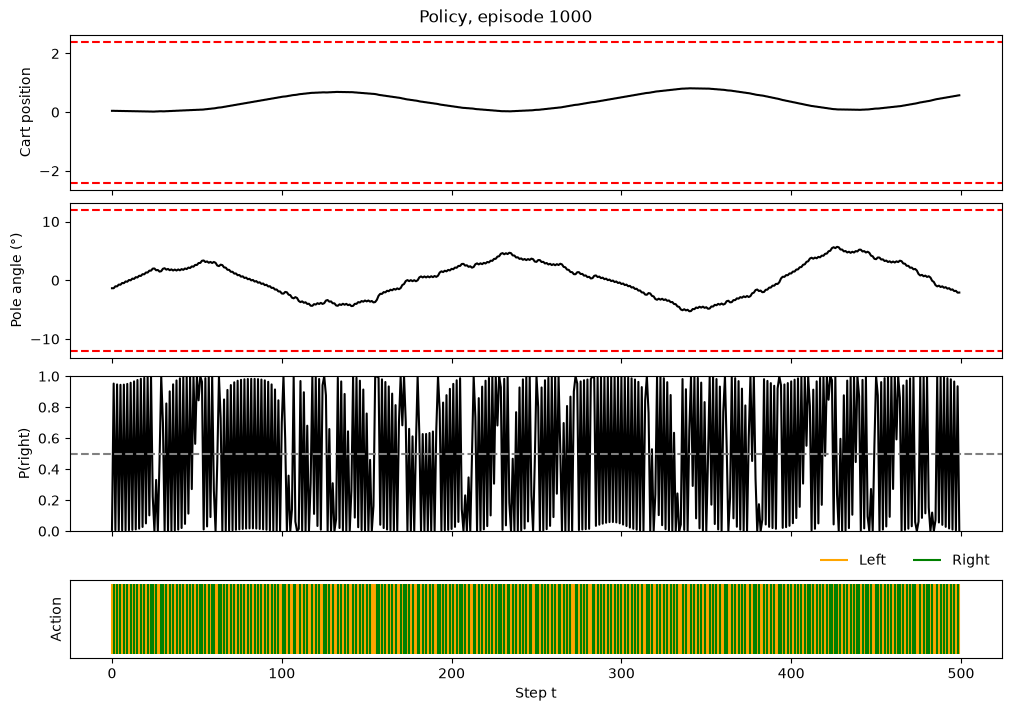

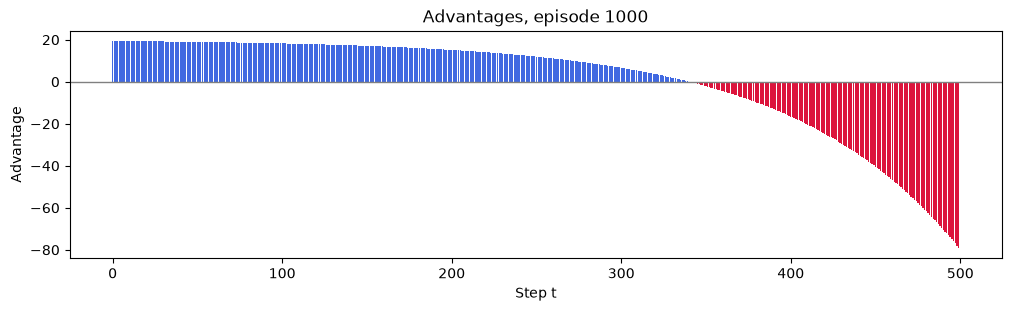

Episode 1000 | return:  500.0 | loss: -0.0983
Training completed in 34.46 seconds.


In [ ]:
history = {"episode": [], "loss": [], "return": [], "baseline": []}

baseline = 0.0

time_start = time.time()
for episode in range(NUM_EPISODES):
    main_key, episode_key = jax.random.split(main_key)
    observations, actions, action_probs, rewards, mask = rollout(
        model, 
        env,
        env_params,
        episode_key,
        MAX_STEPS
    )
    T = int(mask.sum()) # number of valid steps in this episode
    
    # Plot the policy
    if (episode + 1) % CHECK_STEP == 0:
        plot_policy(observations[:T], action_probs[:T], actions[:T], title=f"Policy, episode {episode + 1}")
        plt.show()

    # Compute the returns for this episode
    returns = compute_returns(rewards, GAMMA)

    # Compute the advantages
    advantages = returns - baseline

    # Plot the advantages
    if (episode + 1) % CHECK_STEP == 0:
        plot_advantages(advantages[:T], title=f"Advantages, episode {episode + 1}")
        plt.show()

    # Update the model parameters using the REINFORCE algorithm
    loss = train_step(model, optimizer, observations, actions, advantages, mask)

    # Update the baseline for the next episode
    mean_return = float(jnp.mean(returns, where=mask))
    baseline = BASELINE_DECAY * baseline + (1 - BASELINE_DECAY) * mean_return

    # Compute the total return for this episode
    episode_return = float(rewards.sum())

    history["episode"].append(episode)
    history["loss"].append(float(loss))
    history["return"].append(episode_return)
    history["baseline"].append(baseline)
    if (episode + 1) % CHECK_STEP == 0:
        print(f"Episode {episode + 1:4d} | return: {episode_return:6.1f} | loss: {float(loss):.4f}")

time_end = time.time()
print(f"Training completed in {time_end - time_start:.2f} seconds.")

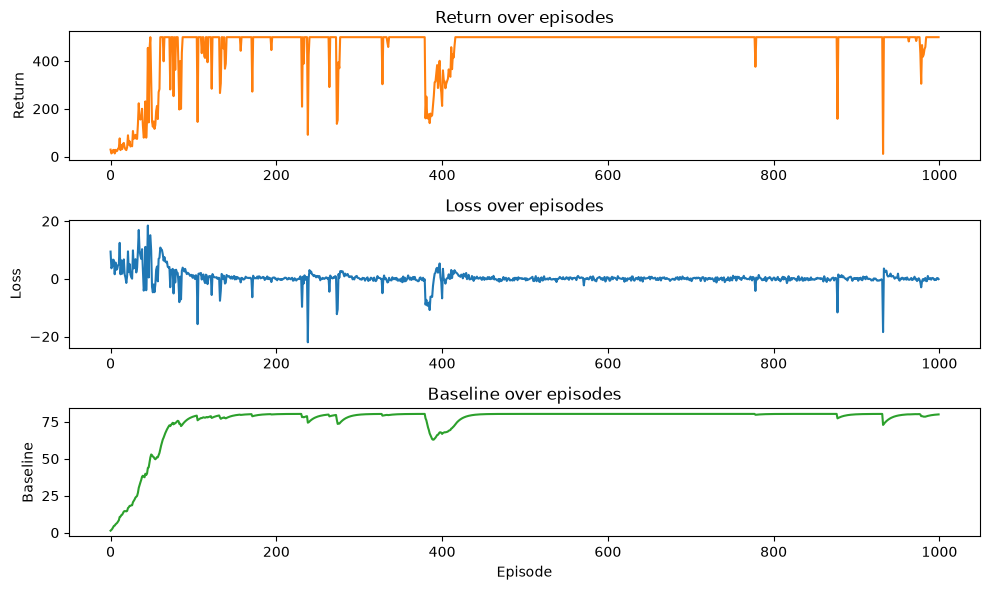

In [8]:
fig, ax = plt.subplots(3, 1, figsize=(10, 6))
ax[0].plot(history["episode"], history["return"], color='C1')
ax[0].set_ylabel("Return")
ax[1].plot(history["episode"], history["loss"])
ax[1].set_ylabel("Loss")
ax[0].set_title("Return over episodes")
ax[1].set_title("Loss over episodes")
ax[2].plot(history["episode"], history["baseline"], color='C2')
ax[2].set_xlabel("Episode")
ax[2].set_ylabel("Baseline")
ax[2].set_title("Baseline over episodes")
plt.tight_layout()

In [9]:
# Save the history plot
fig.savefig("results/reinforce/training.png")

# Save history to json
import json
with open("results/reinforce/training.json", "w") as f:
    json.dump(history, f)

Episode return: 500 (500 frames) -> results/reinforce/cartpole.gif


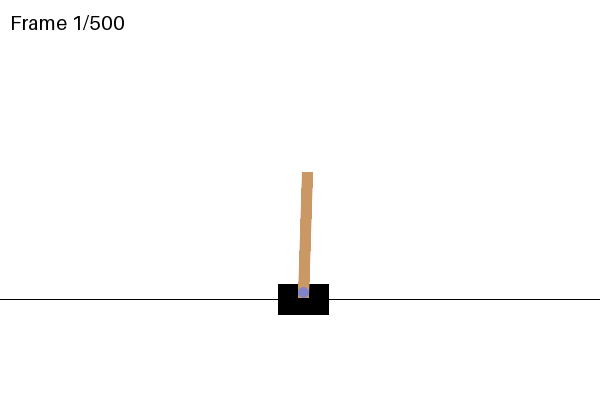

In [10]:
RENDER_SEED = 42

import gymnasium as gym
from PIL import Image, ImageDraw, ImageFont
from IPython.display import Image as DisplayImage, display

GIF_PATH = "results/reinforce/cartpole.gif"

# Separate env that renders frames as RGB arrays
render_env = gym.make("CartPole-v1", render_mode="rgb_array")
state, _ = render_env.reset(seed=RENDER_SEED)
done = False
frames, episode_return = [], 0.0

# Greedy rollout: take the most likely action to show what the policy learned
while not done:
    frames.append(render_env.render())
    logits = model(jnp.asarray(state))
    action = int(jnp.argmax(logits))
    state, reward, terminated, truncated, _ = render_env.step(action)
    episode_return += reward
    done = terminated or truncated

render_env.close()

# Stamp the frame number in the top-left corner
font = ImageFont.load_default(size=20)
images = []
for i, frame in enumerate(frames):
    image = Image.fromarray(frame)
    ImageDraw.Draw(image).text((10, 10), f"Frame {i + 1}/{len(frames)}", fill=(0, 0, 0), font=font)
    images.append(image)

images[0].save(GIF_PATH, save_all=True, append_images=images[1:], duration=20, loop=0)

print(f"Episode return: {episode_return:.0f} ({len(frames)} frames) -> {GIF_PATH}")
display(DisplayImage(filename=GIF_PATH))